Name: <span style="color:hotpink"> Maya Maes-Johnson </span>

Labpartner(s)

In [76]:
#import statements go here
import numpy as np
from scipy.integrate import odeint

# Class 12.2

# Warmup 12.2

Follow up with working on logging into the LSU HPC and finishing the warmup from last time. You may need to run a vpn. Let's get everyone spun up on this. If you're already there, help your fellow students and go dig into the documentation more. We'll do some more on this next week. Report here 1) have you been able to ssh in? 2) have you been able to access the ondemand site and open a jupyter notebook?

<span style="color:hotpink"> 

Still working on this... following along during class lectures.

</span>

# Lecture 12.2

### Announcements
  
We are going to do an advanced lab today!


### Agenda
- Predator prey modeling. We are going to actually do some scientific modelng today!

## Predator Prey Modeling

See what this lab was based on here: 

https://github.com/numerical-mooc/assignment-bank/blob/master/Lessons.and.Assignments/Predator.Prey.Model/Predator.Prey.Model.ipynb

For a more advanced example in predator prey modeling:

https://waterprogramming.wordpress.com/tag/predator-prey/

Modeling the zombie aplocalypse:

https://scipy-cookbook.readthedocs.io/items/Zombie_Apocalypse_ODEINT.html



###  12.2.1 Lotka-Volterra Equations

The Lotka–Volterra equations, also known as the predator–prey equations, are a pair of first-order, non-linear, differential
equations. They are frequently used to describe the dynamics of biological systems in which two species interact, one as a predator and
the other as prey. You can read more about this from Wikipedia <http://en.wikipedia.org/wiki/Lotka-Volterra_equation>.

#### Equations describing the system

 Their populations change with time according to the following pair of equations:

$ dx/dt = x ( \alpha - \beta y  ) $

$ dy/dt = -y( \gamma - \delta x ) $

Where, $x$ is the number of prey (e.g., phytoplankton), $y$ is the number of predators (e.g., zooplankton). $dx/dt, dy/dt$ gives the rate of change of their respective populations over 
time $t$. $\alpha, \beta, \gamma, \delta $ are the parameters describing the interaction between the two species. This models makes some assumptions about 
the predator and prey. You can read about them from the Wikipedia page mentioned above.

The above equations can be written in a slightly different form to interpret the physical meaning of the four parameters used.

1.Rate equation for prey

$dx/dt = \alpha x - \beta x y $

The prey population (x) is presumed to have unlimited supply of food, $\alpha x$ represents the rate of population growth of prey. Rate of decrease of population of prey is assumed to be proportional to the rate at which predator and prey encounter each other, given by $ \beta y x$

2.Rate equation for predator

$ dy/dt = \delta x y -\gamma y $

For the predator population (y), $\delta x y $ gives the rate of growth of predator population. Note that this is similar to the rate of decrease of population of prey. The second term $\gamma y $ gives the rate of population decrease for predators due to natural death or emigration.

### 12.2.2 Numerical solution using Python

A simple python code for solving these equations is shown below.

In [5]:
# import required libraries
import numpy as np
import matplotlib.pyplot as plt

In [6]:
# set the parameters. I just took these from one of the samples, we will play around with them later
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [7]:
#define the time stepping scheme - Euler forward or "shooting" method

def euler_step(u, f, dt):
    """Returns the solution at the next time-step using Euler's method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    
    return u + dt * f(u)

In [8]:
# define the function that represents the Lotka-Volterra equations
# u is the x,y state of the system, what the population is at a given time.
# u = [x,y] on array with both the predetor and prey variables

def f(u):
    """Returns the rate of change of species
    
    Parameters
    ----------
    u : array of float
        array containing the solution at time n.
        
    Returns
    -------
    dudt : array of float
        array containing the RHS given u.
    """
    x = u[0]
    y = u[1]
    return np.array([x*(alpha - beta*y), -y*(gamma - delta*x)])


In [9]:
# Now solve the system


# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])


In [10]:
u_euler

array([[10.,  2.],
       [ 0.,  0.],
       [ 0.,  0.],
       ...,
       [ 0.,  0.],
       [ 0.,  0.],
       [ 0.,  0.]], shape=(1501, 2))

In [11]:
n = 0
u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [12]:
u_euler

array([[10.  ,  2.  ],
       [ 9.86,  2.12],
       [ 0.  ,  0.  ],
       ...,
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ]], shape=(1501, 2))

In [13]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [14]:
u_euler

array([[10.        ,  2.        ],
       [ 9.86      ,  2.12      ],
       [ 9.7077616 ,  2.244232  ],
       ...,
       [ 0.87954346,  0.04493602],
       [ 0.88786462,  0.04353381],
       [ 0.89627944,  0.04217898]], shape=(1501, 2))

We will now plot the variation of population for each species with time.

In [15]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

Text(0.5, 1.0, 'predator prey model')

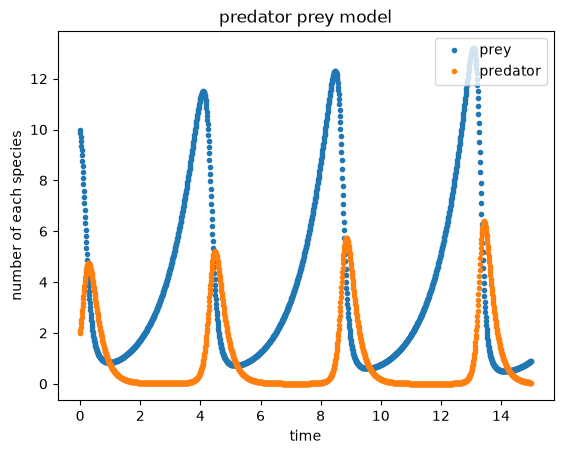

In [16]:
plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Let's think a bit about what this solution means, what is going on here?

<span style="color:hotpink"> As the prey decreases due to predation, the predator population decreases. When the predator population is low, prey population increases. </span>

What happens if we start with different initial conditions? Like more prey and less predators.

In [17]:
# initial conditions (initial populations):
x0 = 15. # initial prey amount
y0 = 0.001 # initial predator amount
t0 = 0.

In [18]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

In [19]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

What happened?

Text(0.5, 1.0, 'predator prey model')

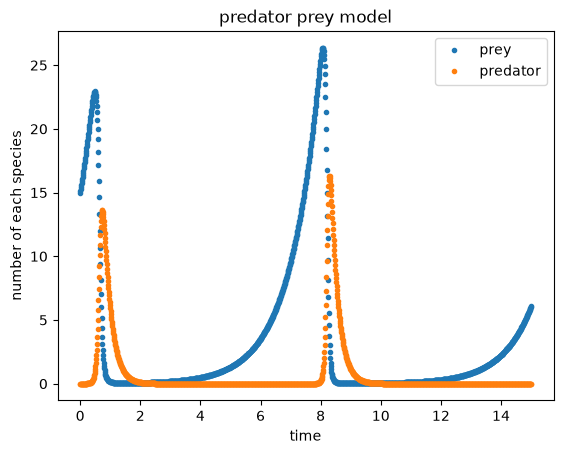

In [20]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What if we start with the same amount of prey and predators?

In [21]:
# set the parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [22]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [23]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

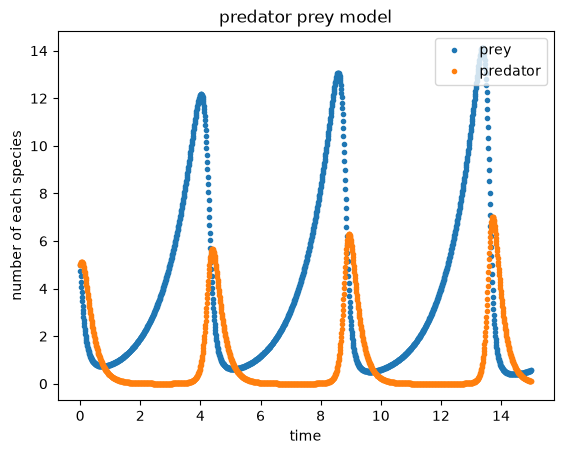

In [24]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

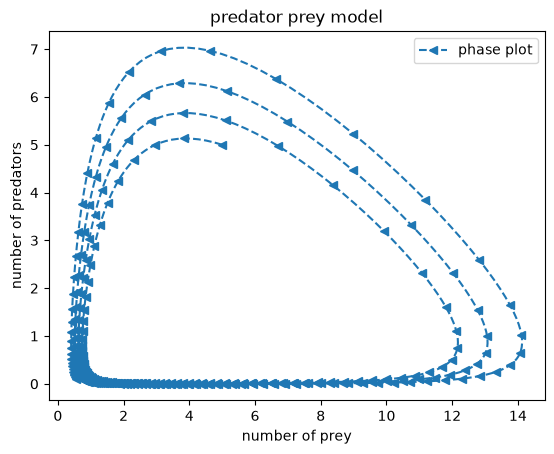

In [25]:
plt.plot(x_euler, y_euler, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

What happened?

<span style="color:hotpink"> This phase plot shows the relationship between predator and prey populations. It is similar to what we have seen in previous plots, but it is a different way to visualize this relationship. </span>

Let's mess around with the model parameters. What if the prey grow faster?

In [26]:
# set the parameters
alpha = 10.
beta = 1.2
gamma = 4.
delta = 1.

In [27]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [28]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

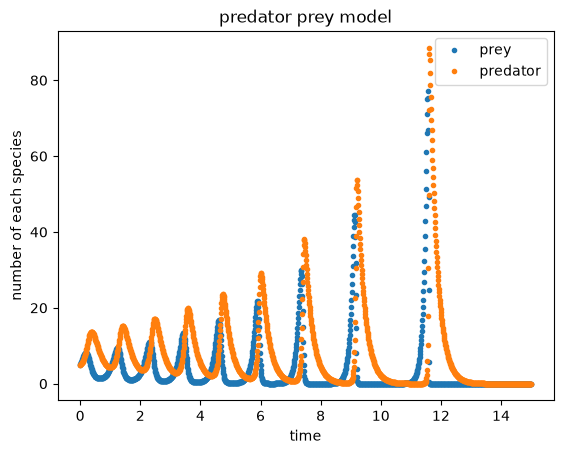

In [29]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What happened?

<span style="color:hotpink"> The prey population grows rapidly and the predator population follows. </span>

### 12.2.3 System behavior

A better understanding of the system behavior can be obtained by a phase plot of the population of predators vs. the population of prey. It will tell us if the system sustains or collapses over time. For the choice of parameters $ \alpha, \beta, \gamma $ and $ \delta $ made above, we see that the maximum population of each species keeps increasing each cycle. You can read more about that in the Wikipedia link mentioned above.

Text(0.5, 1.0, 'predator prey model')

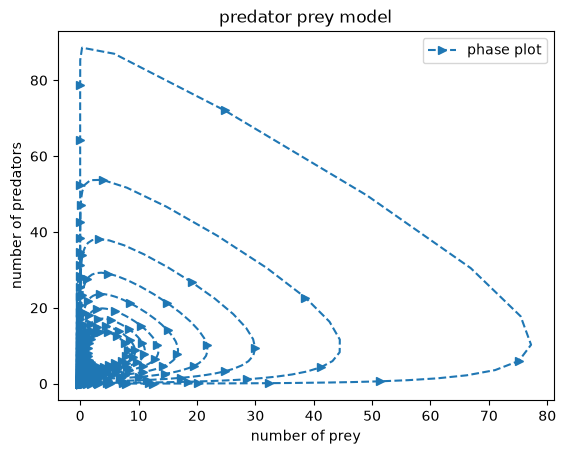

In [30]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

# Lab 12.2

#### E.1 How does timestep affect the solution?
Modify the timestep (or time increment) dt. How does this affect your solutions? Plot both the timeseries and the phase plots. Try making dt 10 times bigger (dt = 0.1) and 10 times smaller. Describe what happens to your results. What happens if you make dt 100 times smaller?

In [31]:
# Set params
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [32]:
# dt - 10x bigger
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.10                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

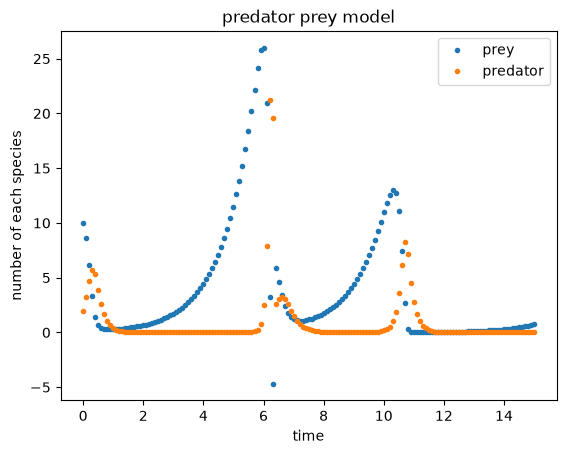

In [33]:
# timeseries - 10x bigger
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

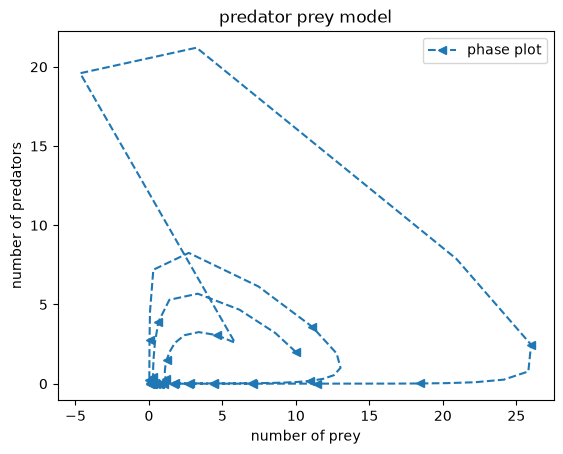

In [34]:
# Phase plot - 10x bigger
plt.plot(x_euler, y_euler, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

<span style="color:hotpink">

At a dt of 10x bigger, the time series looks quite sparse and it is difficult to see the trend between the prey and predator populations. The phase plot does not show a clear, stable pattern.

</span>

In [35]:
# dt - 10x smaller
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.001                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

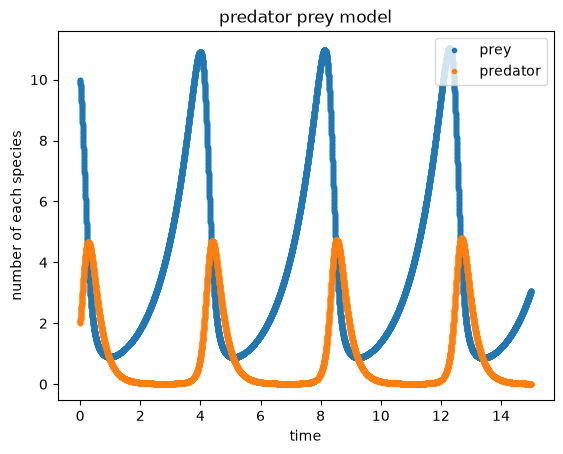

In [36]:
# timeseries - 10x smaller
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

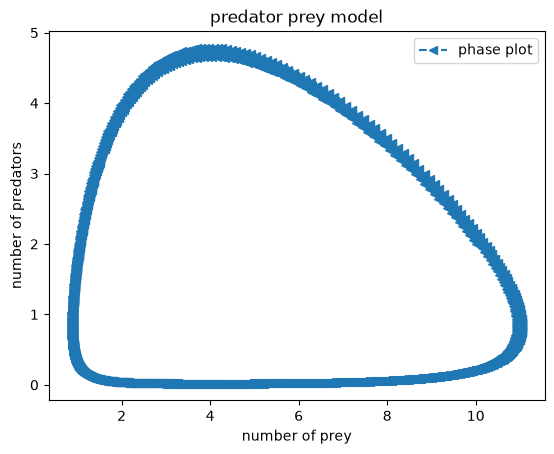

In [37]:
# Phase plot - 10x smaller
plt.plot(x_euler, y_euler, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

<span style="color:hotpink">

At a much smaller timespan, the timeseries becomes very dense with points. The phase plot develops what looks to be like closed orbits.

</span>

In [38]:
# dt - 100x smaller
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.0001                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

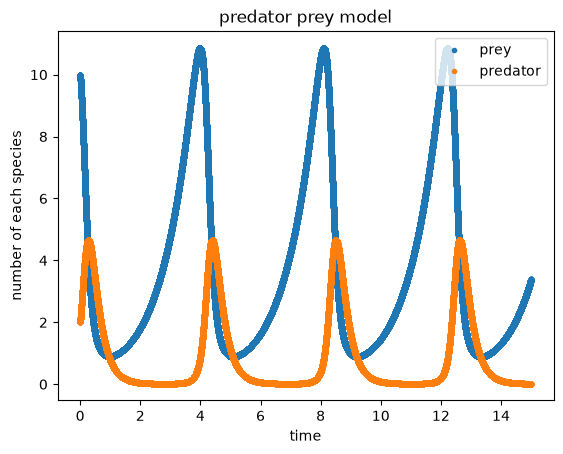

In [39]:
# timeseries - 100x smaller
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

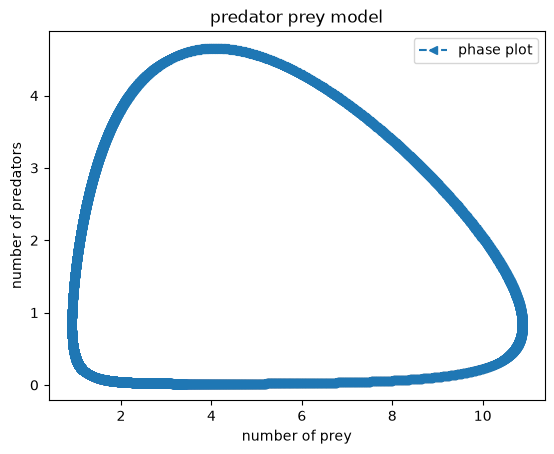

In [40]:
# Phase plot - 100x smaller
plt.plot(x_euler, y_euler, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

<span style="color:hotpink">

At a timestep of 100x smaller, there doesn't seem to be much difference betweeen a dt of 0.001 and a dt of 0.0001, suggesting a diminishing returns in the accuracy of the model at smaller dt. To save time and promote efficiency, a timestep at around 0.01 is likely the most efficient while preserving accuracy.

</span>

#### E.2 Adding the steady state

The steady state(s) of the system are found by setting the population equations to zero, that is the solution to when the population is not changing. This is also called a "fixed point" of the equations, since if the populations start there they stay there, i.e. are fixed.

Find the steady states of the system using algebra. Plot the fixed point (steady state population) of the system on both the timeseries and phase space plots. Describe where the fixed point is in the phase space plot and plot it. What happens if you start at the steady state? What happens if you start near the steady state?

$\alpha x - \beta x y  = 0$

$\delta x y -\gamma y  = 0$



<span style="color:hotpink">

$\textbf{Equilibrium Pts}$

$x (\alpha - \beta y) = 0$ --> $x = 0$, $y = \alpha / \beta$

$y (\delta x - \gamma) = 0$ --> $y = 0$, $x = \gamma / \delta$

- $x = 0$ and $y = 0$ represents the steady state when both populations are 0.
- $x = \gamma / \delta$ and $y = \alpha / \beta$ represents when both populations are in equilibrium.
</span>

In [41]:
# Set params
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [42]:
x_steady = gamma / delta
print(x_steady)
y_steady = alpha / beta
print(y_steady)

4.0
0.8333333333333334


In [43]:
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = x_steady # steady state prey amount
y0 = y_steady # steady state predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model - start at steady state')

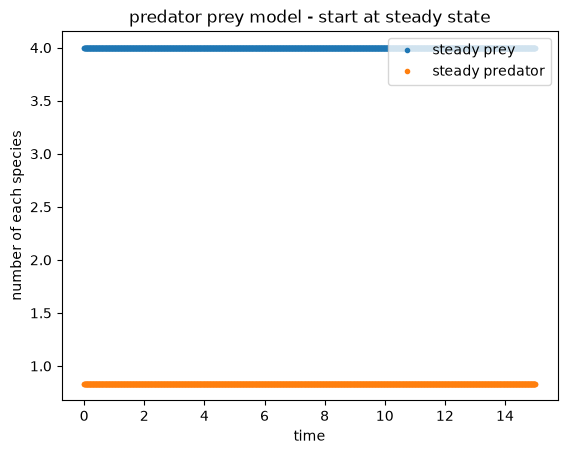

In [44]:
# timeseries - start at steady state
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'steady prey ')
plt.plot(time, y_euler, '.', label = 'steady predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model - start at steady state")

Text(0.5, 1.0, 'predator prey model - start at steady state')

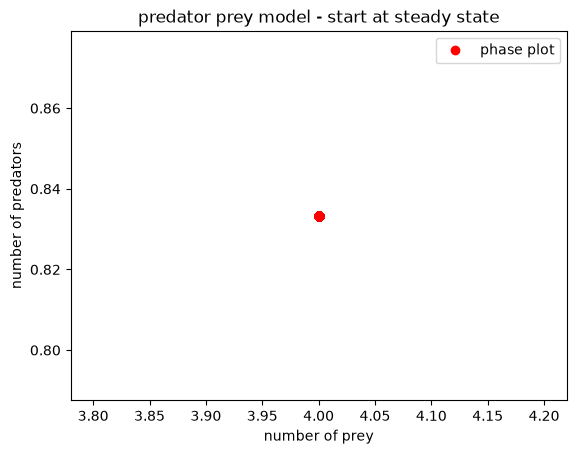

In [45]:
# Phase plot - start at steady state
plt.plot(x_euler, y_euler, 'o', color= "red", markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model - start at steady state")

<span style="color:hotpink">

Starting at the steady state, there is no change in population, the populations stay constant in time.

</span>

In [46]:
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = x_steady + 0.1 # near steady state prey amount
y0 = y_steady + 0.1 # near steady state predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model - start at steady state')

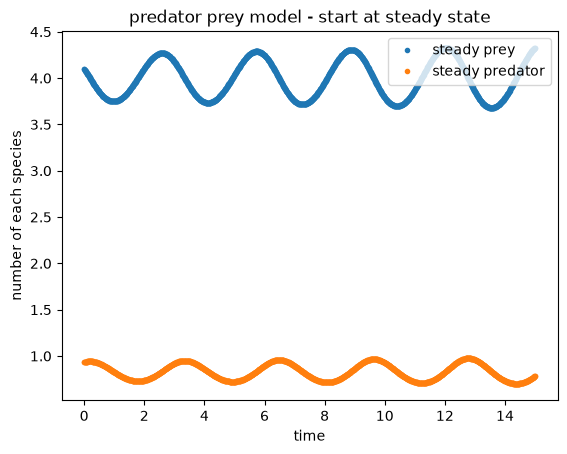

In [47]:
# timeseries - start at steady state
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'steady prey ')
plt.plot(time, y_euler, '.', label = 'steady predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model - start at steady state")

Text(0.5, 1.0, 'predator prey model - start at steady state')

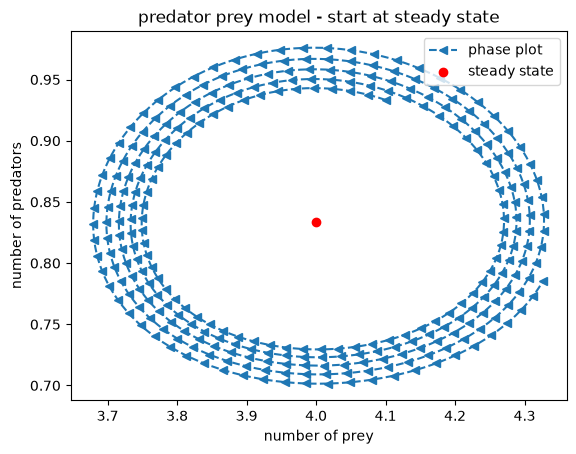

In [48]:
# Phase plot - start at steady state
plt.plot(x_euler, y_euler, '<--', markevery=5, label = 'phase plot')
plt.scatter(x_steady, y_steady, color='red', label = 'steady state')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model - start at steady state")

<span style="color:hotpink">

Near the steady state, the populations fluctuate slightly. The phase plot shows a stable limit cycle abouth the equilibrium point.

</span>    

#### E.3 A better algorithm
Do Exercise 1 again with a fourth order time stepping method called "Runge-Kutta 4" whose algorithm is given below. How do your answers differ? How does the dt, the timestep, affect your answer using this "higher order" algorithm?

In [49]:
def RK4(u,f,dt):
    # Runge Kutta 4th order method
    """Returns the solution at the next time-step using Runge Kutta fourth order (RK4) method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    #calculate slopes
    k1 = f(u)
    u1 = u + (dt/2.)*k1
    k2 = f(u1)
    u2 = u + (dt/2.)*k2
    k3 = f(u2)
    u3 = u + dt*k3
    k4 = f(u3)
    return u + (dt/6.)*(k1 + 2.*k2 + 2.*k3 + k4)

In [50]:
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# imput initial conditions
u_rk4[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_rk4[n+1] = RK4(u_rk4[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

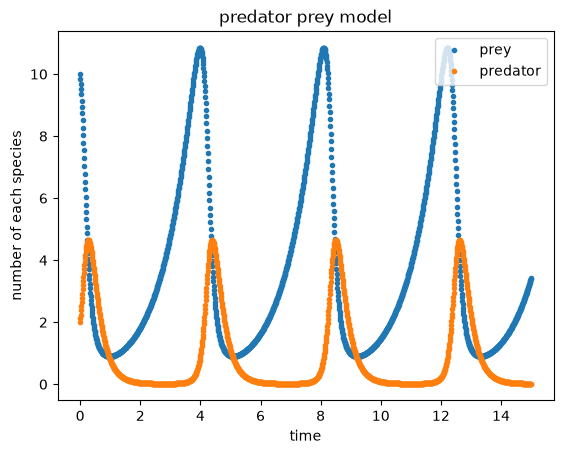

In [51]:
time = np.linspace(0.0, T,N)
x_rk4 = u_rk4[:,0]
y_rk4 = u_rk4[:,1]

plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

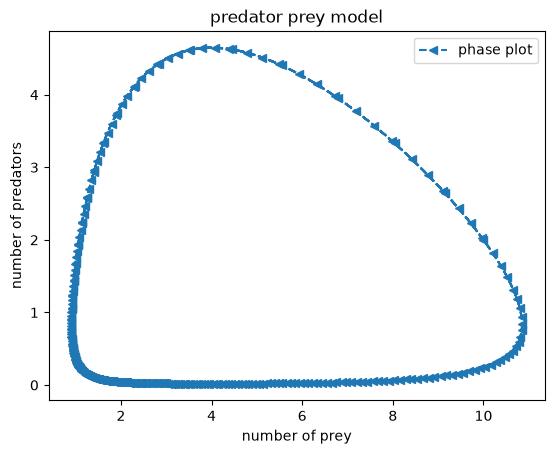

In [52]:
plt.plot(x_rk4, y_rk4, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

In [53]:
# bigger dt
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.1                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# imput initial conditions
u_rk4[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_rk4[n+1] = RK4(u_rk4[n], f, dt)

Text(0.5, 1.0, 'predator prey model - dt = 0.1')

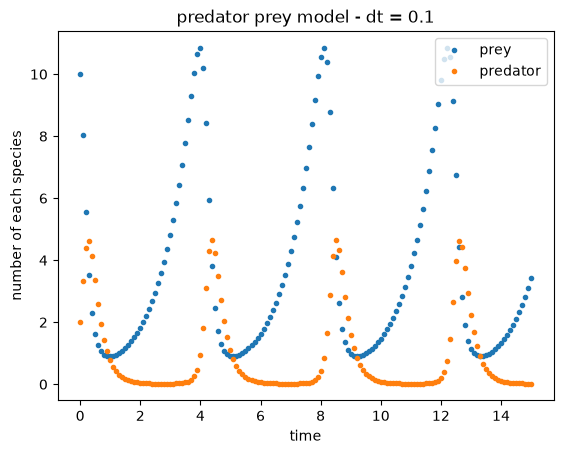

In [54]:
time = np.linspace(0.0, T,N)
x_rk4 = u_rk4[:,0]
y_rk4 = u_rk4[:,1]

plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model - dt = 0.1")

Text(0.5, 1.0, 'predator prey model - dt = 0.1')

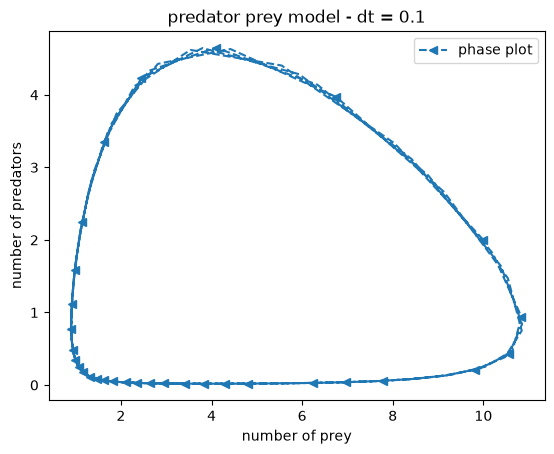

In [55]:
plt.plot(x_rk4, y_rk4, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model - dt = 0.1")

In [56]:
# smaller dt
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.001                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_rk4 = np.zeros((N, 2))

# imput initial conditions
u_rk4[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_rk4[n+1] = RK4(u_rk4[n], f, dt)

Text(0.5, 1.0, 'predator prey model - dt = 0.001')

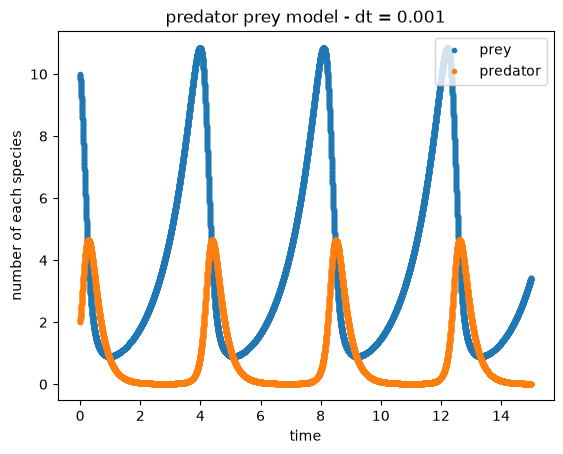

In [57]:
time = np.linspace(0.0, T,N)
x_rk4 = u_rk4[:,0]
y_rk4 = u_rk4[:,1]

plt.plot(time, x_rk4, '.', label = 'prey ')
plt.plot(time, y_rk4, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model - dt = 0.001")

Text(0.5, 1.0, 'predator prey model - dt = 0.001')

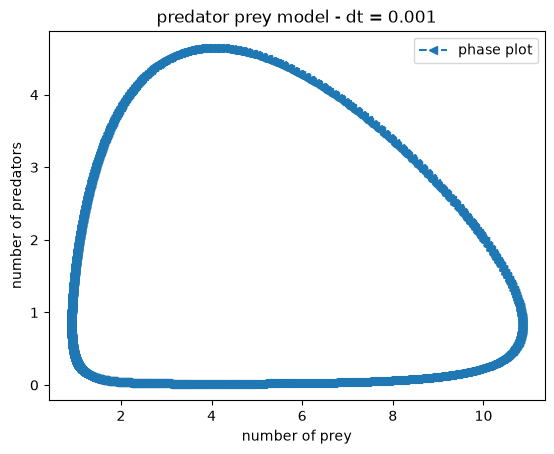

In [58]:
plt.plot(x_rk4, y_rk4, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model - dt = 0.001")

<span style="color:hotpink">

The results from using Runge-Kutta 4 are similar to that of the euler stepping method, but for the larger dt, the method doesn't "break" while plotting the phase plot. Because RK4 is a higher-order method, it has greater stability compared to the euler method.

</span> 

#### E.4 Exploring parameter space
Vary the interactions between species by changing $\alpha, \beta, \gamma, \delta$ and see what happens to the population evolution as well as phase plots. How does changing each parameter individually affect the system?

<span style="color:hotpink">

$\textbf{Changing } \alpha$

Recall that alpha represents the birth rate for the prey population.

</span>

In [59]:
# set the parameters
alpha = 10.
beta = 1.2
gamma = 4.
delta = 1.

In [60]:
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

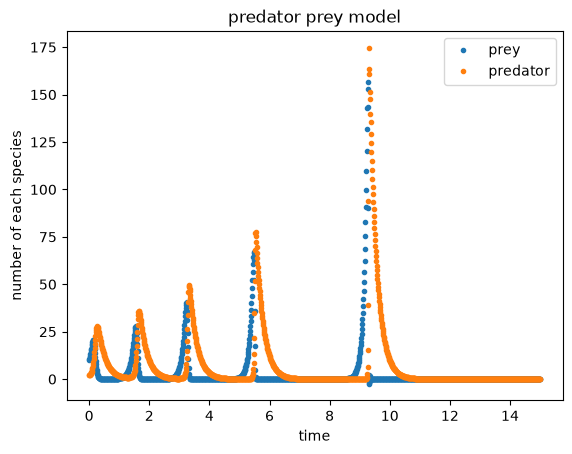

In [61]:
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

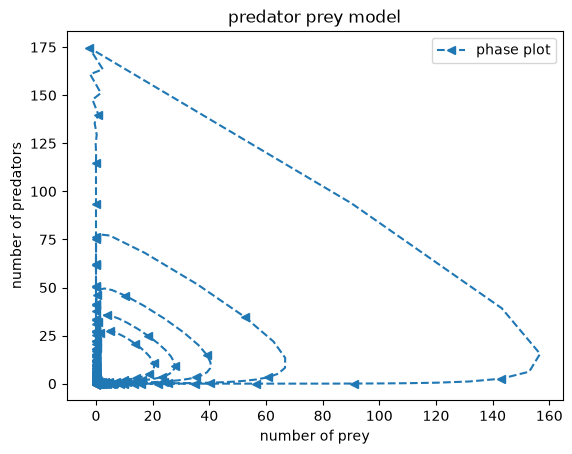

In [62]:
plt.plot(x_euler, y_euler, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

<span style="color:hotpink">

When the prey birth rate ($\alpha$) starts at a higher value, the population continues to grow with each cycle of predation. The predator population follows this trend as well. On the phase plot, the orbits grow outward. 

</span>

<span style="color:hotpink">

$\textbf{Changing } \beta$

Recall that beta represents the death rate for the prey population due to predation.

</span>

In [63]:
# set the parameters
alpha = 1.
beta = .01
gamma = 4.
delta = 1.

In [64]:
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

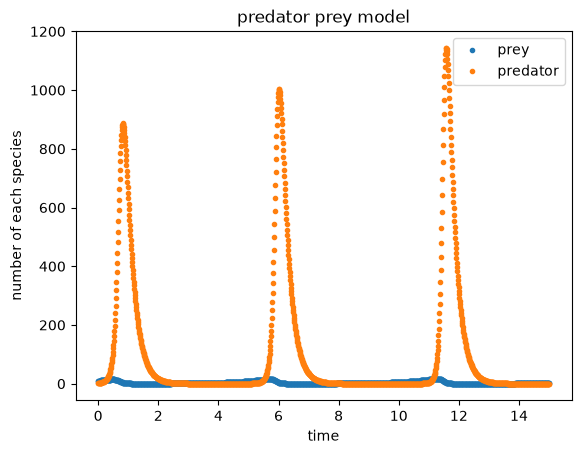

In [65]:
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

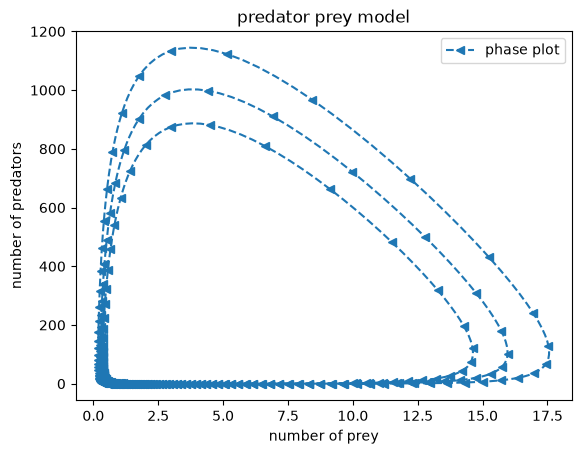

In [66]:
plt.plot(x_euler, y_euler, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

<span style="color:hotpink">

Timeseries:
- Increasing the prey death rate lead to decline in prey and predator populations followed by a sharp spike in prey population with a minor increase in predator population
- Decreasing $\beta$ lead to an increase in the predator population

Phase Diagram:
- Increasing $\beta$ leads to a phase diagram with few orbits
- When $\beta$ is decreased, the phase diagram is populated with more orbits where we see more growth in the predator population as the prey population increases.

</span>

<span style="color:hotpink">

$\textbf{Changing } \gamma$

Recall that gamma represents the death rate for the predator population.

</span>

In [67]:
# set the parameters
alpha = 1.
beta = 1.2
gamma = 0.4
delta = 1.

In [68]:
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

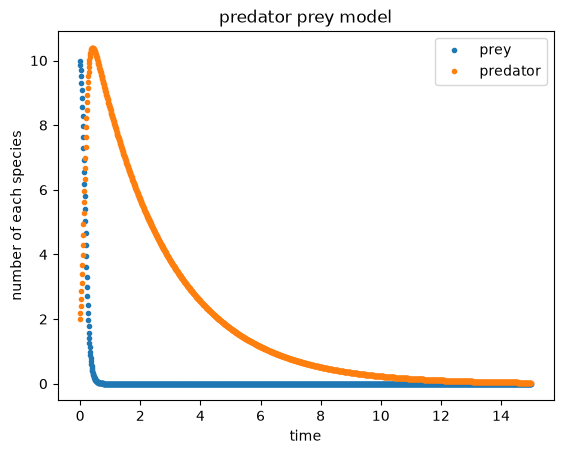

In [69]:
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

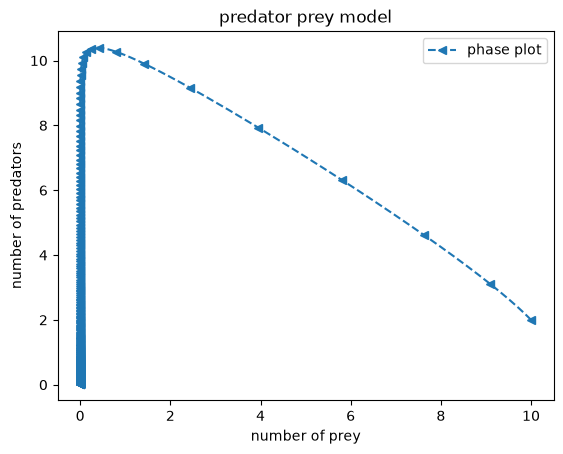

In [70]:
plt.plot(x_euler, y_euler, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

<span style="color:hotpink">

Timeseries:
- Increasing $\gamma$ leads to an increase in the overall prey population
- Decreasing $\gamma$ leads to an intial sharp increase in the predator population followed by a decrease. Both populations go to 0.

Phase Diagram:
- Increasing $\gamma$ leads to a phase diagram with multiple orbits around the equilibrium point
- Decreasing $\gamma$ leads to a phase plot with no complete orbits because the populations both die off and are unable to rebound.

</span>

<span style="color:hotpink">

$\textbf{Changing } \delta$

Recall that delta represents the increase in predator population as a result of the presence of prey.

</span>

In [71]:
# set the parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 10

In [72]:
# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

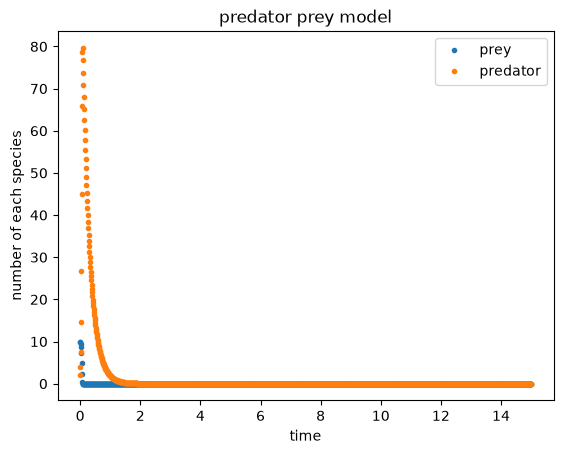

In [73]:
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

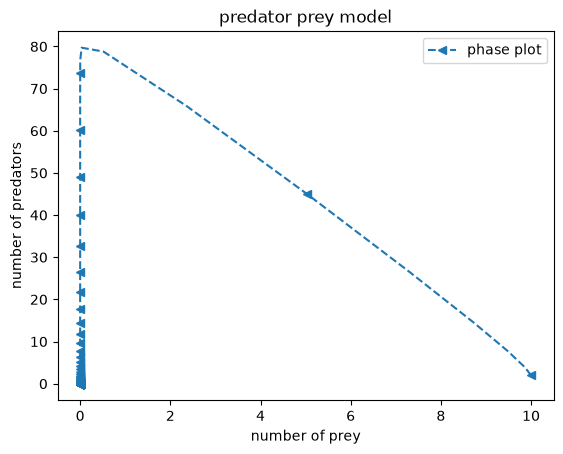

In [74]:
plt.plot(x_euler, y_euler, '<--', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

<span style="color:hotpink">

- Increasing $\delta$ resulted in a timeseries and phase plot similar to when $\gamma$ was decreased.
- Decreasing $\delta$ resulted in a timeseries and phase diagram that showed larger prey populations compared to predator populations.

</span>

#### E.5 (Advanced, required for grad students)
Modify the differential equations to include other types of interactions. See advanced predator prey example link at the top for ideas. You might add in a self-eating (i.e. $-ay^2$) term into the predator equation. Or do the zombie apocalypse example linked above.

<span style="color:hotpink"> 

For this section of the lab, I will try to implement a SIR model (which shows the spread of disease) following the example from https://scipython.com/books/book2/chapter-8-scipy/examples/the-sir-epidemic-model/

- The rate of the susceptible population in time is given by $\frac{dS}{dt} = - \frac{\beta SI}{N}$, where $\beta$ is the contract rate

- The rate of the infected population in time is given by $\frac{dI}{dt} = \frac{\beta SI}{N} - \gamma I$, where $\gamma$ is the mean recovery rate

- The rate of the recovered population in time is given by $\frac{dR}{dt} = \gamma I$

</span>

In [78]:
# Set parameters:
N = 1000 # total population
infected_0 = 1 # initial infected
recovered_0 = 0 # initial recovered
susceptible_0 = N - infected_0 - recovered_0 # assumption: recovered individuals are not longer susceptible to the disease
beta = 0.2
gamma = 0.1

# Set time grid
time = np.linspace(0, 160, 160)

In [79]:
# Create function to handle derivatives:
def deriv(y, t, N, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    return dSdt, dIdt, dRdt

In [82]:
y_0 = susceptible_0, infected_0, recovered_0 # Set initial conditions vector
ret = odeint(deriv, y_0, time, args=(N, beta, gamma)) 
# we have not used odeint in class, but it is a scipy function that numerically integrates a system of odes 
# by using the Adams and backward differentiation method!
S, I, R = ret.T # transpose the vector

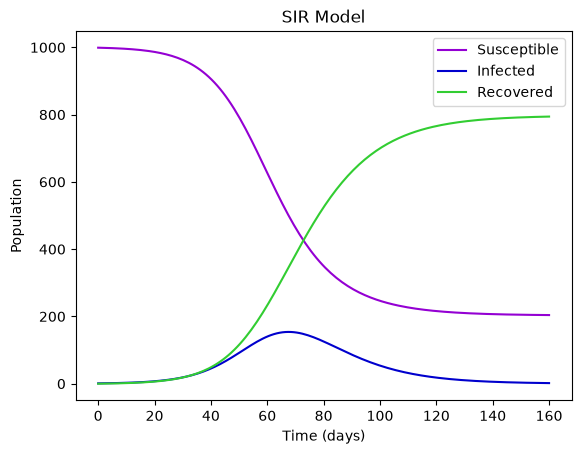

In [86]:
plt.plot(time, S, color = "darkviolet", label = "Susceptible")
plt.plot(time, I, color = "mediumblue", label = "Infected")
plt.plot(time, R, color = "limegreen", label = "Recovered")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.title("SIR Model")
plt.legend()

<span style="color:hotpink"> What if we change the contract rate to be higher (disease is more infectious)? </span>

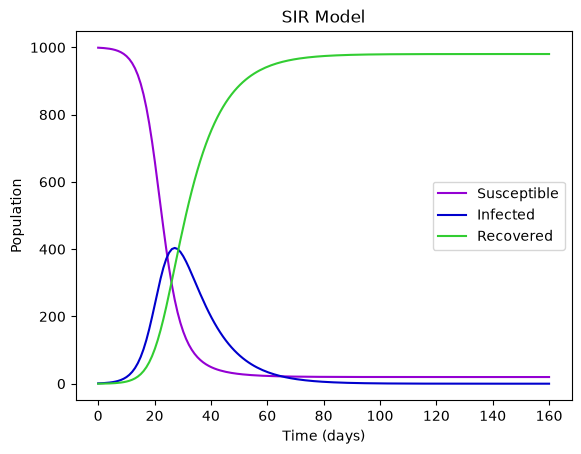

In [87]:
beta = 0.4

y_0 = susceptible_0, infected_0, recovered_0 # Set initial conditions vector
ret = odeint(deriv, y_0, time, args=(N, beta, gamma)) 
# we have not used odeint in class, but it is a scipy function that numerically integrates a system of odes 
# by using the Adams and backward differentiation method!
S, I, R = ret.T # transpose the vector

plt.plot(time, S, color = "darkviolet", label = "Susceptible")
plt.plot(time, I, color = "mediumblue", label = "Infected")
plt.plot(time, R, color = "limegreen", label = "Recovered")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.title("SIR Model")
plt.legend()